In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm


import os
import sys
import numpy as np
import torch
import matplotlib.pyplot as plt
import pandas as pd
from datasets import load_dataset

In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"

print(device)

if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

cuda
NVIDIA GeForce RTX 4090


In [3]:
#Import SAM2
from sam2.build_sam import build_sam2
from sam2.sam2_image_predictor import SAM2ImagePredictor

print("SAM2 imported successfully")

SAM2 imported successfully


In [7]:
#Find SAM2 checkpoint
possible_checkpoints = [
    "/home/zahranadeem/checkpoints/sam2_hiera_small.pt",
    "/home/zahranadeem/thesis/sam2/checkpoints/sam2_hiera_small.pt",
    "/home/zahranadeem/thesis/sam2_repo/checkpoints/sam2_hiera_small.pt",
]

checkpoint = None

for p in possible_checkpoints:
    if os.path.exists(p):
        checkpoint = p
        break

print("Checkpoint:", checkpoint)

assert checkpoint is not None, "SAM2 checkpoint not found"

Checkpoint: /home/zahranadeem/checkpoints/sam2_hiera_small.pt


In [8]:
#Load SAM2 
config = "sam2_hiera_s.yaml"

sam2_model = build_sam2(
    config,
    checkpoint,
    device=device
)

predictor = SAM2ImagePredictor(sam2_model)

print("SAM2 loaded successfully")

SAM2 loaded successfully


In [9]:
#Load VegANN
from datasets import load_dataset
dataset = load_dataset(
            "simonMadec/VegAnn"
)

print(dataset)
print(dataset["train"][10].keys())

DatasetDict({
    train: Dataset({
        features: ['image', 'mask', 'System', 'Orientation', 'latitude', 'longitude', 'date', 'LocAcc', 'Species', 'Owner', 'Dataset-Name', 'TVT-split1', 'TVT-split2', 'TVT-split3', 'TVT-split4', 'TVT-split5'],
        num_rows: 3775
    })
})
dict_keys(['image', 'mask', 'System', 'Orientation', 'latitude', 'longitude', 'date', 'LocAcc', 'Species', 'Owner', 'Dataset-Name', 'TVT-split1', 'TVT-split2', 'TVT-split3', 'TVT-split4', 'TVT-split5'])


In [10]:
def compute_iou_dice(pred_mask, gt_mask):
    pred = pred_mask.astype(bool)
    gt = gt_mask.astype(bool)

    intersection = np.logical_and(pred, gt).sum()
    union = np.logical_or(pred, gt).sum()

    iou = intersection / union if union > 0 else 0

    dice = (
        2 * intersection
    ) / (
        pred.sum() + gt.sum()
    ) if (pred.sum() + gt.sum()) > 0 else 0

    return iou, dice

In [11]:
#Helper GT box
def get_gt_box(gt_mask, padding=0):
    ys, xs = np.where(gt_mask)

    if len(xs) == 0 or len(ys) == 0:
        return None

    H, W = gt_mask.shape

    x1 = max(xs.min() - padding, 0)
    y1 = max(ys.min() - padding, 0)
    x2 = min(xs.max() + padding, W - 1)
    y2 = min(ys.max() + padding, H - 1)

    return np.array([x1, y1, x2, y2])

In [12]:
#Helper Center point prompt 
def run_sam2_point_prompt(image):
    H, W = image.shape[:2]

    point = np.array([[W // 2, H // 2]])
    label = np.array([1])

    predictor.set_image(image)

    masks, scores, logits = predictor.predict(
        point_coords=point,
        point_labels=label,
        multimask_output=True
    )

    best_idx = scores.argmax()
    pred_mask = masks[best_idx] > 0

    return pred_mask

In [13]:
#Helper SAM2 box prompt 
def run_sam2_box_prompt(image, box):
    predictor.set_image(image)

    masks, scores, logits = predictor.predict(
        box=box,
        multimask_output=True
    )

    best_idx = scores.argmax()
    pred_mask = masks[best_idx] > 0

    return pred_mask

In [17]:
from scipy import ndimage

In [30]:
def get_vegetation_box_from_image_full(image, padding=10, percentile=70):
    img = image.astype(np.float32) / 255.0

    r = img[:, :, 0]
    g = img[:, :, 1]
    b = img[:, :, 2]

    exg = 2 * g - r - b
    threshold = np.percentile(exg, percentile)

    veg_mask = exg > threshold

    ys, xs = np.where(veg_mask)

    if len(xs) == 0 or len(ys) == 0:
        H, W = image.shape[:2]
        return np.array([W//4, H//4, 3*W//4, 3*H//4]), veg_mask

    H, W = image.shape[:2]

    x1 = max(xs.min() - padding, 0)
    y1 = max(ys.min() - padding, 0)
    x2 = min(xs.max() + padding, W - 1)
    y2 = min(ys.max() + padding, H - 1)

    return np.array([x1, y1, x2, y2]), veg_mask

In [32]:
auto_box, estimated_veg_mask = get_vegetation_box_from_image_full(
    image,
    padding=10,
    percentile=70
)

auto_pred = run_sam2_box_prompt(image, auto_box)
auto_iou, auto_dice = compute_iou_dice(auto_pred, gt_mask)

print(f"Auto Full Box + SAM2 IoU: {auto_iou*100:.2f}%")
print(f"Auto Full Box + SAM2 Dice: {auto_dice*100:.2f}%")

Auto Full Box + SAM2 IoU: 66.13%
Auto Full Box + SAM2 Dice: 79.62%


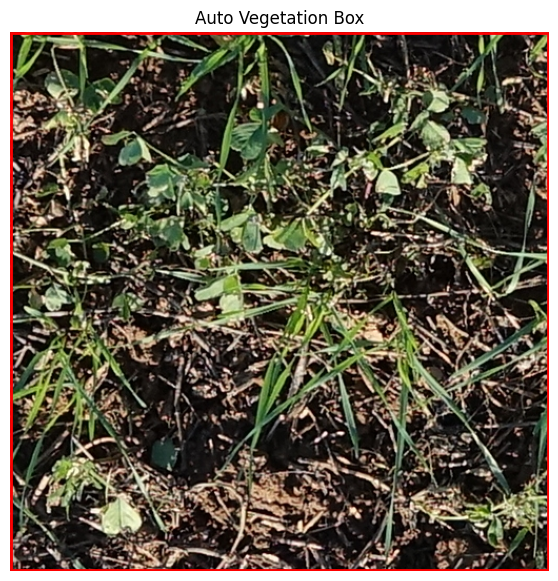

In [33]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

x1, y1, x2, y2 = auto_box

fig, ax = plt.subplots(figsize=(7,7))
ax.imshow(image)

rect = patches.Rectangle(
    (x1, y1),
    x2 - x1,
    y2 - y1,
    linewidth=2,
    edgecolor="red",
    facecolor="none"
)

ax.add_patch(rect)
ax.set_title("Auto Vegetation Box")
ax.axis("off")
plt.show()

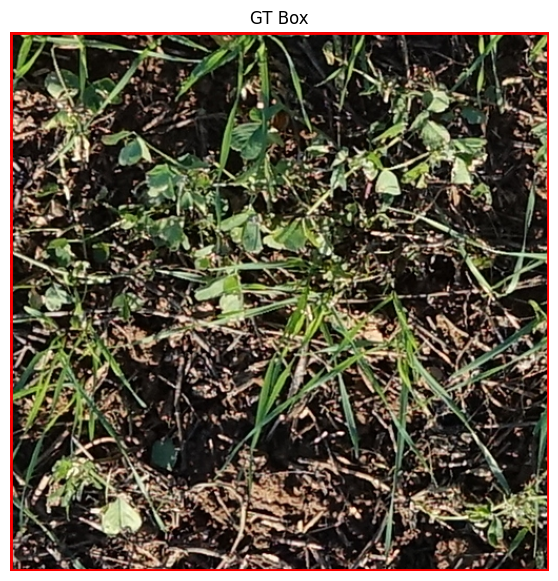

In [34]:
x1, y1, x2, y2 = gt_box

fig, ax = plt.subplots(figsize=(7,7))
ax.imshow(image)

rect = patches.Rectangle(
    (x1, y1),
    x2 - x1,
    y2 - y1,
    linewidth=2,
    edgecolor="red",
    facecolor="none"
)

ax.add_patch(rect)
ax.set_title("GT Box")
ax.axis("off")
plt.show()

Species: Mix
GT box: [  0   0 511 511]
Auto box: [  0   0 511 511]


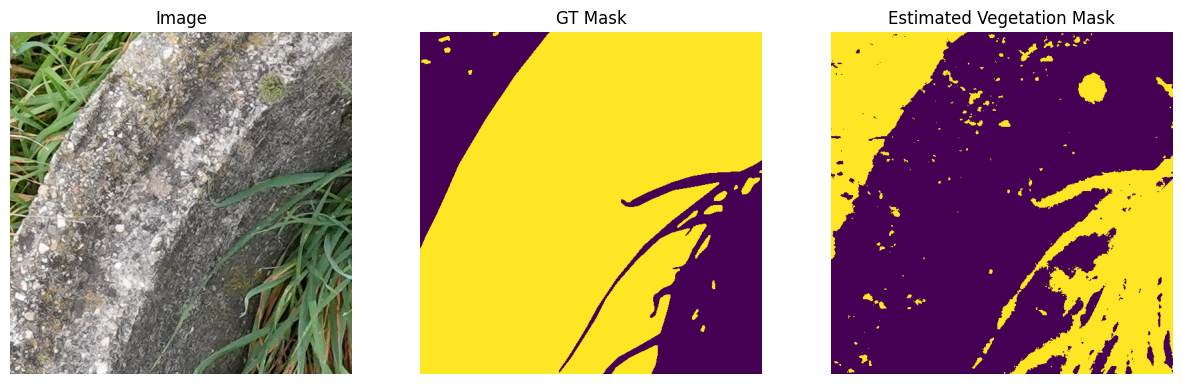

In [42]:
idx = 0

sample = dataset["train"][idx]

image = np.array(sample["image"])
mask = np.array(sample["mask"])

# VegAnn: vegetation/foreground = 0, background = 255
gt_mask = mask == 0

gt_box = get_gt_box(gt_mask)
auto_box, estimated_veg_mask = get_vegetation_box_from_image_full(image)

print("Species:", sample["Species"])
print("GT box:", gt_box)
print("Auto box:", auto_box)

plt.figure(figsize=(15, 5))

plt.subplot(131)
plt.imshow(image)
plt.title("Image")
plt.axis("off")

plt.subplot(132)
plt.imshow(gt_mask)
plt.title("GT Mask")
plt.axis("off")

plt.subplot(133)
plt.imshow(estimated_veg_mask)
plt.title("Estimated Vegetation Mask")
plt.axis("off")

plt.show()

In [43]:
print("GT mask unique:", np.unique(gt_mask))
print("Estimated mask unique:", np.unique(estimated_veg_mask))

print("GT vegetation pixels:", gt_mask.sum())
print("Estimated vegetation pixels:", estimated_veg_mask.sum())

GT mask unique: [False  True]
Estimated mask unique: [False  True]
GT vegetation pixels: 193311
Estimated vegetation pixels: 77600


In [44]:
point_pred = run_sam2_point_prompt(image)
point_iou, point_dice = compute_iou_dice(point_pred, gt_mask)

box_pred = run_sam2_box_prompt(image, gt_box)
box_iou, box_dice = compute_iou_dice(box_pred, gt_mask)

auto_pred = run_sam2_box_prompt(image, auto_box)
auto_iou, auto_dice = compute_iou_dice(auto_pred, gt_mask)

print(f"SAM2 + Center Point IoU: {point_iou*100:.2f}%")
print(f"SAM2 + Center Point Dice: {point_dice*100:.2f}%")

print(f"SAM2 + GT Box IoU: {box_iou*100:.2f}%")
print(f"SAM2 + GT Box Dice: {box_dice*100:.2f}%")

print(f"Auto Box + SAM2 IoU: {auto_iou*100:.2f}%")
print(f"Auto Box + SAM2 Dice: {auto_dice*100:.2f}%")

SAM2 + Center Point IoU: 94.36%
SAM2 + Center Point Dice: 97.10%
SAM2 + GT Box IoU: 86.71%
SAM2 + GT Box Dice: 92.88%
Auto Box + SAM2 IoU: 86.71%
Auto Box + SAM2 Dice: 92.88%


In [49]:
N = 50

all_results = []

for idx in tqdm(range(N)):

    sample = dataset["train"][idx]

    image = np.array(sample["image"])
    mask = np.array(sample["mask"])

    gt_mask = mask == 0

    if gt_mask.sum() == 0:
        continue

    # SAM2 center point
    point_pred = run_sam2_point_prompt(image)
    point_iou, point_dice = compute_iou_dice(point_pred, gt_mask)

    # SAM2 GT box
    gt_box = get_gt_box(gt_mask)

    if gt_box is None:
        continue

    box_pred = run_sam2_box_prompt(image, gt_box)
    box_iou, box_dice = compute_iou_dice(box_pred, gt_mask)

    # Automatic vegetation box + SAM2
    auto_box, estimated_veg_mask = get_vegetation_box_from_image_full(
        image,
        padding=10,
        percentile=70
    )

    auto_pred = run_sam2_box_prompt(image, auto_box)
    auto_iou, auto_dice = compute_iou_dice(auto_pred, gt_mask)

    all_results.append({
        "idx": idx,
        "Species": sample["Species"],
        "Point_IoU": point_iou,
        "Point_Dice": point_dice,
        "GT_Box_IoU": box_iou,
        "GT_Box_Dice": box_dice,
        "Auto_Box_IoU": auto_iou,
        "Auto_Box_Dice": auto_dice
    })

results_50 = pd.DataFrame(all_results)

results_50.head()

100%|██████████| 50/50 [00:04<00:00, 11.35it/s]


,idx,Species,Point_IoU,Point_Dice,GT_Box_IoU,GT_Box_Dice,Auto_Box_IoU,Auto_Box_Dice
0,0,Mix,0.943637,0.971001,0.867146,0.928847,0.867146,0.928847
1,1,Mix,0.000000,0.000000,0.011068,0.021894,0.010100,0.019997
2,2,Mix,0.078397,0.145395,0.000938,0.001874,0.004840,0.009634
3,3,Mix,0.941947,0.970106,0.957374,0.978223,0.957374,0.978223
4,4,Mix,0.001945,0.003883,0.072526,0.135244,0.072526,0.135244


In [50]:
summary = pd.DataFrame({
    "Method": [
        "SAM2 + Center Point",
        "SAM2 + GT Box",
        "Auto Vegetation Box + SAM2"
    ],
    "Mean IoU": [
        results_50["Point_IoU"].mean(),
        results_50["GT_Box_IoU"].mean(),
        results_50["Auto_Box_IoU"].mean()
    ],
    "Mean Dice": [
        results_50["Point_Dice"].mean(),
        results_50["GT_Box_Dice"].mean(),
        results_50["Auto_Box_Dice"].mean()
    ]
})

summary

,Method,Mean IoU,Mean Dice
0,SAM2 + Center Point,0.105227,0.123633
1,SAM2 + GT Box,0.412786,0.503835
2,Auto Vegetation Box + SAM2,0.401483,0.486845


In [51]:
summary_percent = summary.copy()

summary_percent["Mean IoU"] = summary_percent["Mean IoU"].apply(lambda x: f"{x*100:.2f}%")
summary_percent["Mean Dice"] = summary_percent["Mean Dice"].apply(lambda x: f"{x*100:.2f}%")

summary_percent

,Method,Mean IoU,Mean Dice
0,SAM2 + Center Point,10.52%,12.36%
1,SAM2 + GT Box,41.28%,50.38%
2,Auto Vegetation Box + SAM2,40.15%,48.68%


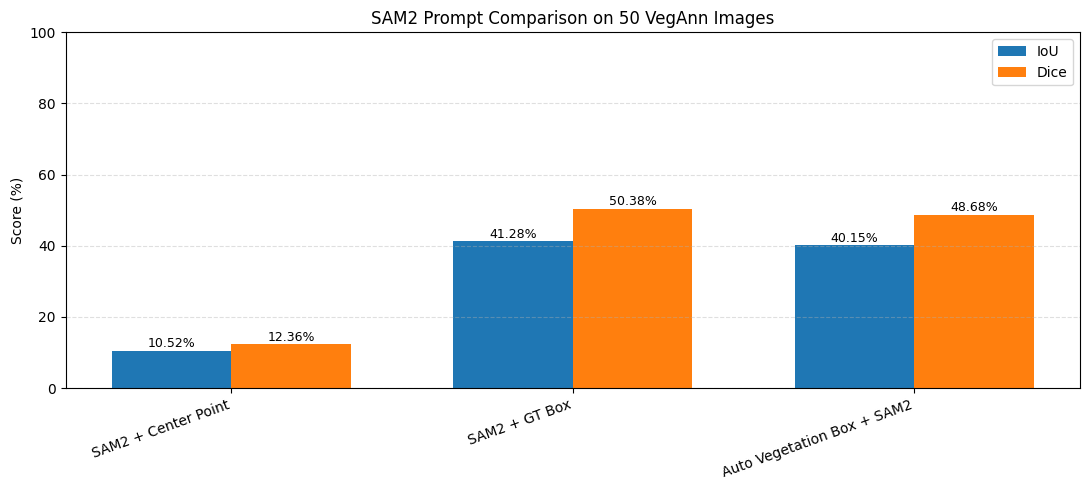

In [52]:
methods = summary["Method"].tolist()

iou_scores = [x * 100 for x in summary["Mean IoU"].tolist()]
dice_scores = [x * 100 for x in summary["Mean Dice"].tolist()]

x = np.arange(len(methods))
width = 0.35

plt.figure(figsize=(11, 5))

plt.bar(
    x - width / 2,
    iou_scores,
    width,
    label="IoU"
)

plt.bar(
    x + width / 2,
    dice_scores,
    width,
    label="Dice"
)

plt.xticks(
    x,
    methods,
    rotation=20,
    ha="right"
)

plt.ylabel("Score (%)")
plt.title("SAM2 Prompt Comparison on 50 VegAnn Images")
plt.ylim(0, 100)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)

for i, v in enumerate(iou_scores):
    plt.text(
        i - width / 2,
        v + 1,
        f"{v:.2f}%",
        ha="center",
        fontsize=9
    )

for i, v in enumerate(dice_scores):
    plt.text(
        i + width / 2,
        v + 1,
        f"{v:.2f}%",
        ha="center",
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    "sam2_vegann_50_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

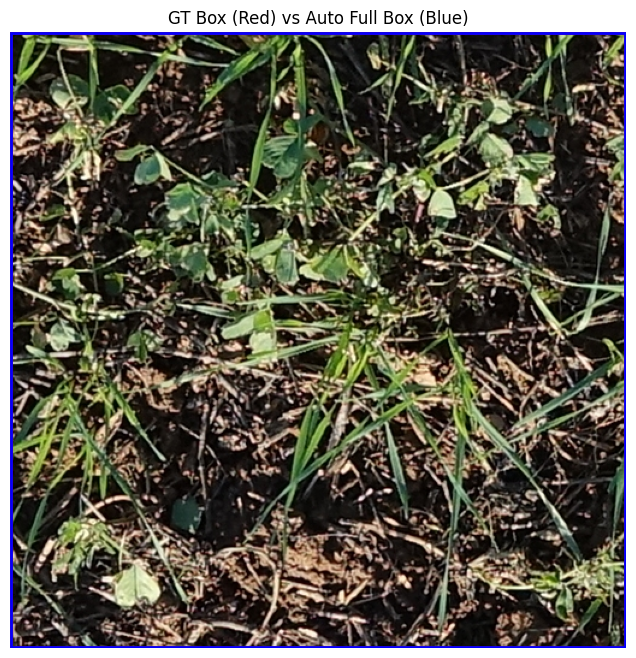

In [53]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(8,8))
ax.imshow(image)

# GT box
x1, y1, x2, y2 = gt_box
gt_rect = patches.Rectangle(
    (x1, y1),
    x2-x1,
    y2-y1,
    linewidth=2,
    edgecolor='red',
    facecolor='none',
    label='GT'
)
ax.add_patch(gt_rect)

# Auto box
x1, y1, x2, y2 = auto_box
auto_rect = patches.Rectangle(
    (x1, y1),
    x2-x1,
    y2-y1,
    linewidth=2,
    edgecolor='blue',
    facecolor='none',
    label='Auto'
)
ax.add_patch(auto_rect)

plt.title("GT Box (Red) vs Auto Full Box (Blue)")
plt.axis("off")
plt.show()